In [28]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import math
import numpy as np

from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import lifelines # pip install lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import logrank_test

In [2]:
dataset = pd.read_csv("bone_marrow.csv", index_col=0)
event = dataset["survival_status"]
duration = dataset["survival_time"]
data = dataset.drop(["survival_status","survival_time"], axis = 1)
data

,Recipientage,CD34kgx10d6,CD3dkgx10d8,Donorage,Rbodymass,Riskgroup,Stemcellsource,RecipientRh
0,9.6,7.20,5.38,22.830137,35.0,1.0,1.0,1.0
1,4.0,4.50,0.41,23.342466,20.6,0.0,0.0,1.0
2,6.6,7.94,0.42,26.394521,23.4,0.0,0.0,1.0
3,18.1,4.25,0.14,39.684932,50.0,0.0,0.0,1.0
4,1.3,51.85,13.05,33.358904,9.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...
182,12.9,11.08,4.39,37.575342,44.0,1.0,1.0,0.0
183,13.9,4.64,4.47,22.895890,44.5,1.0,1.0,1.0
184,10.4,7.73,4.73,27.347945,33.0,0.0,1.0,1.0
185,8.0,15.41,1.91,27.780822,24.0,0.0,1.0,1.0


In [3]:
dataset.columns

Index(['Recipientage', 'CD34kgx10d6', 'CD3dkgx10d8', 'Donorage', 'Rbodymass',
       'Riskgroup', 'Stemcellsource', 'RecipientRh', 'survival_time',
       'survival_status'],
      dtype='object')

This notebook is split into two parts

`First part:`

We will perform KMeans clustering. Our objective is to find the optimal number of clusters (K). Methods like DBSCAN do not provide an specific number of clusters but rather rely on the radius value, it also leaves some points unassigned, additionally, methods like hierarchical clustering require finding specific dendrogram height cuts.

K-Means suffers from random initialization, which  is why KMeans++ will be used
The number of clusters will be evaluated through different metrics and methods to guarantee robustness.

`Second part:`

We will apply survival functions with Kaplan-Meier and Cox Regression for each of the cluster groups. Analyzing their main differences and conclusions

# Clustering

Evaluation will be done with the metrics

`Calinski-Harabasz`: Ratio of the sum of inter-cluster dispersion and the sum of intra-cluster dispersion for all clusters. The higher the better

`Davies-Bouldin`: Average similarity of each cluster with a cluster more similar to it. The lower the average similarity is, the better. Similarity is defined as the ratio of within-cluster scatter to between-cluster distances

`Silhouette Score`: How well each data point fits within its assignated cluster and how well separated it is from other clusters. Returns a value between 1 and -1. 0 indicates overlap, negative values means a point has been incorrectly assigned.

`Elbow Method`: We compute the Within-Cluster Sum of Squares (WCSS) for various values of k. We will obtain a plot in a decreasing manner, we will select the cluster located at the elbow.


In [4]:
K = list(range(2,9))

wcss, ch_scores, db_scores, sh_scores = [], [], [], []
for k in K:
    kmeans = KMeans(n_clusters=k, random_state= 42, init="k-means++").fit(data)
    wcss.append(kmeans.inertia_)
    labels = kmeans.labels_
    ch_scores.append(calinski_harabasz_score(data, labels))
    db_scores.append(davies_bouldin_score(data, labels))
    sh_scores.append(silhouette_score(data, labels))

metrics_df = pd.DataFrame({
    "K": K,
    "WCSS": wcss,
    "Silhouette Score": sh_scores,
    "Calinski-Harabasz": ch_scores,
    "Davies-Bouldin": db_scores
})

print(metrics_df.to_string(index=False))

 K         WCSS  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
 2 52633.373053          0.432840         202.022924        0.860731
 3 40229.865910          0.311730         159.805613        1.041943
 4 36085.031838          0.298061         125.135370        0.950182
 5 28533.369762          0.290116         130.083821        1.012366
 6 25778.583314          0.277337         118.423567        1.091840
 7 22365.023345          0.258867         117.699173        1.104504
 8 20054.715812          0.266202         114.827775        1.125697


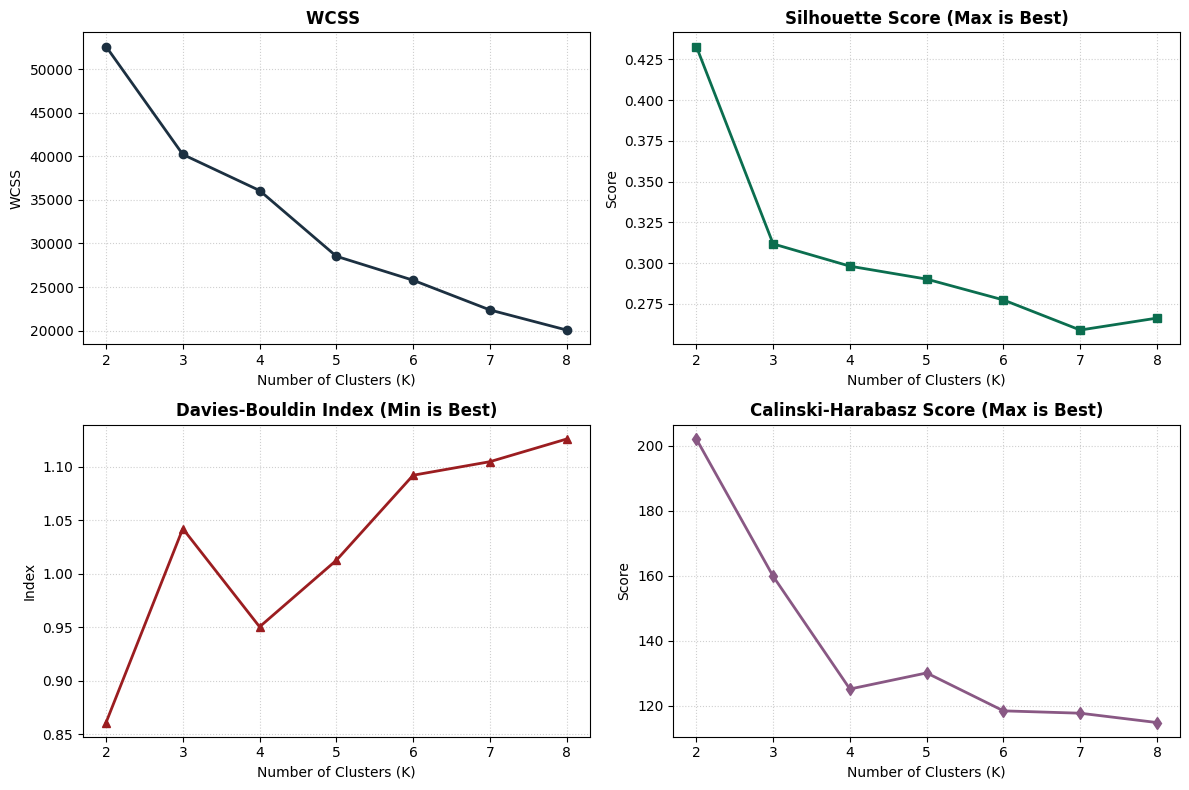

In [5]:

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

#  WCSS /Inertia (Elbow)
axs[0, 0].plot(K, wcss, marker="o", color="#1C3041", linewidth=2)
axs[0, 0].set_title("WCSS ", fontweight="bold")
axs[0, 0].set_xlabel("Number of Clusters (K)")
axs[0, 0].set_ylabel("WCSS")
axs[0, 0].grid(True, linestyle=":", alpha=0.6)

# Silhouette Score (Higher = Better)
axs[0, 1].plot(K, sh_scores, marker="s", color="#0B6E4F", linewidth=2)
axs[0, 1].set_title("Silhouette Score (Max is Best)", fontweight="bold")
axs[0, 1].set_xlabel("Number of Clusters (K)")
axs[0, 1].set_ylabel("Score")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)

#  Davies-Bouldin Index (Lower = Better)
axs[1, 0].plot(K, db_scores, marker="^", color="#9B1D20", linewidth=2)
axs[1, 0].set_title("Davies-Bouldin Index (Min is Best)", fontweight="bold")
axs[1, 0].set_xlabel("Number of Clusters (K)")
axs[1, 0].set_ylabel("Index")
axs[1, 0].grid(True, linestyle=":", alpha=0.6)

# Calinski-Harabasz Score (Higher = Better)
axs[1, 1].plot(K, ch_scores, marker="d", color="#895884", linewidth=2)
axs[1, 1].set_title("Calinski-Harabasz Score (Max is Best)", fontweight="bold")
axs[1, 1].set_xlabel("Number of Clusters (K)")
axs[1, 1].set_ylabel("Score")
axs[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

For the silhouette score, we see that K=2 is the best by a large margin.

For davies boulding, the minimum value is reached for K = 2 with a local minimum for K = 4.

The Calinski-Harabasz score shows a maximum value for K=2, with a local maximum for K = 5.

For the elbow method, we see that it constantly decreases but without a clear drop or elbow-shape (One of the flaws of this method)

K=2 seems to be the best performing model, followed by K=3.

We will perform PCA analysis with the different clustering classes to see if data is being correctly grouped

##  PCA

We have to take into account our first two PCA components explain around 50% of the variability in the data, therefore, they should be carefully checked.

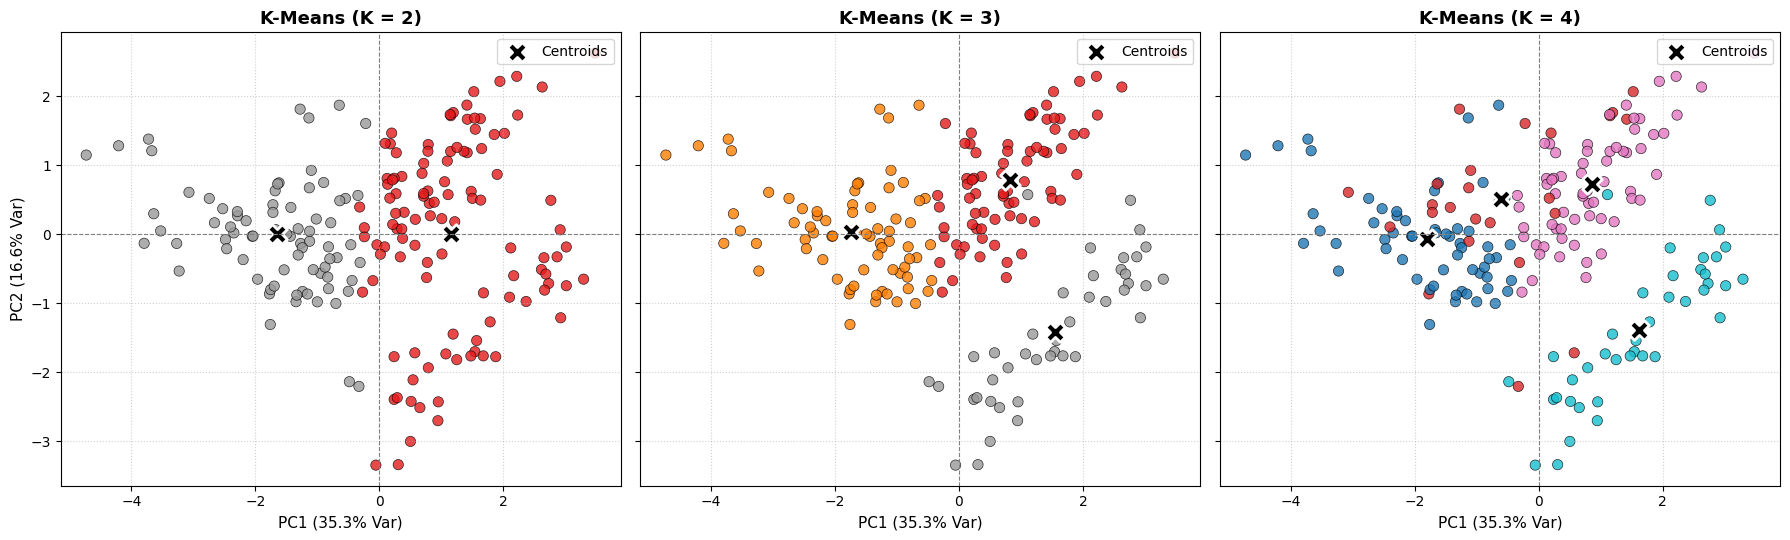

In [7]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(scaled_data)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 4]

for i, k in enumerate(k_values):
    ax = axs[i]
    kmeans = KMeans(n_clusters=k, random_state=42, init="k-means++", n_init=10)
    labels = kmeans.fit_predict(scaled_data)

    # Project cluster centroids to the 2D PCA space
    centers_2d = pca_2d.transform(kmeans.cluster_centers_)

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot projected centroids
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Centroids",
    )

    ax.set_title(f"K-Means (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

Our plots support the idea that the split should be done into two separate groups.

We can see that this split is not too accurate, this could be due to KMeans algorithm, whcih assumes spherical clusters and many times cannot distinguish different clusters. We will therefore use Spectral Clustering to see if it can split it better

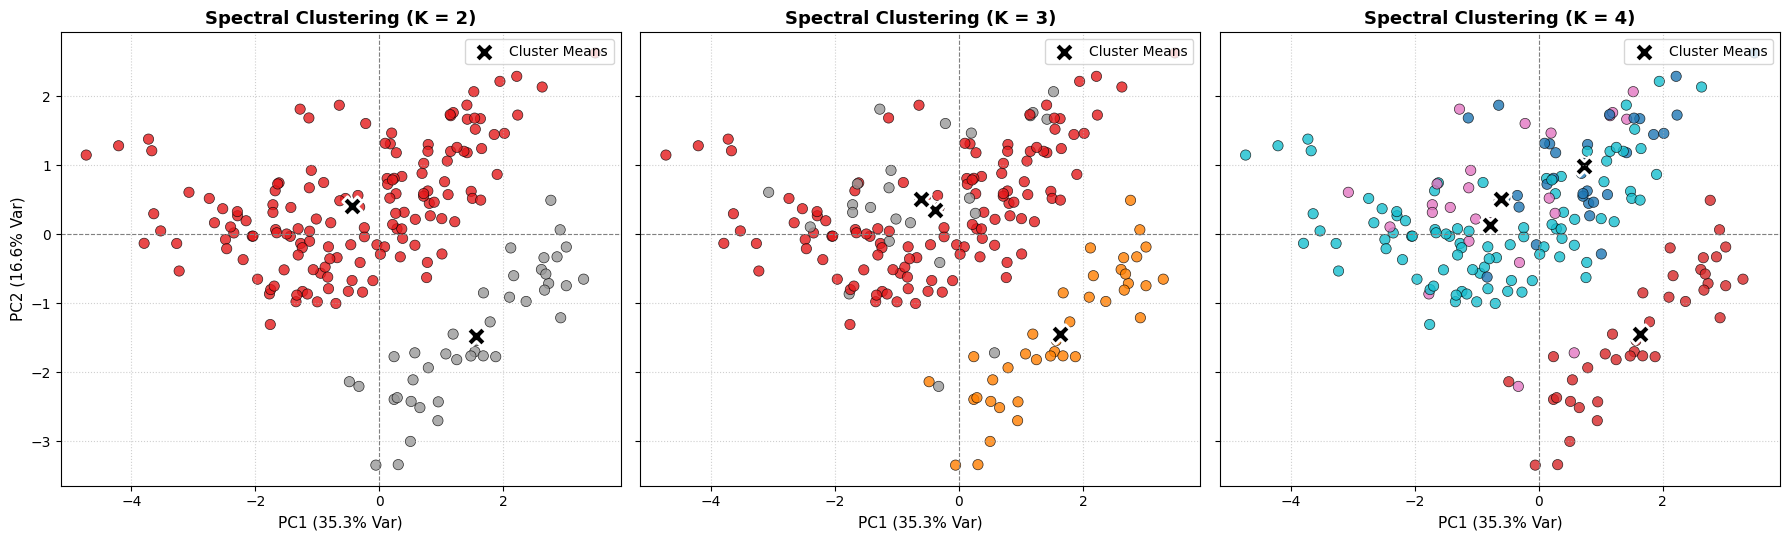

In [12]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)
pca_2d = PCA(n_components=2)
x_pca_2d = pca_2d.fit_transform(scaled_data)
var_exp = pca_2d.explained_variance_ratio_ * 100

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
k_values = [2, 3, 4]

for i, k in enumerate(k_values):
    ax = axs[i]
    
    # Spectral Clustering with nearest-neighbors affinity graph
    spectral = SpectralClustering(
        n_clusters=k,
        affinity='nearest_neighbors',  
        n_neighbors=15,                
        assign_labels='kmeans',
        random_state=42,
        n_jobs=-1
    )
    labels = spectral.fit_predict(scaled_data)

    centers_2d = np.array([
        x_pca_2d[labels == cluster_id].mean(axis=0)
        for cluster_id in range(k)
    ])

    scatter = ax.scatter(
        x_pca_2d[:, 0],
        x_pca_2d[:, 1],
        c=labels,
        cmap="Set1" if k <= 3 else "tab10",
        s=55,
        alpha=0.8,
        edgecolors="k",
        linewidths=0.5,
    )

    # Plot empirical cluster means
    ax.scatter(
        centers_2d[:, 0],
        centers_2d[:, 1],
        c="black",
        marker="X",
        s=200,
        linewidths=2,
        edgecolors="white",
        label="Cluster Means",
    )

    ax.set_title(f"Spectral Clustering (K = {k})", fontsize=13, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=11)
    if i == 0:
        ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=11)

    ax.grid(True, linestyle=":", alpha=0.6)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

As we can see, Spectral Clustering seems to perform a good division on 2D. However, this data projection in PCA only explains about 50% of the data which may not be completely correct. Threfore, we will plot it in 3D just to be sure

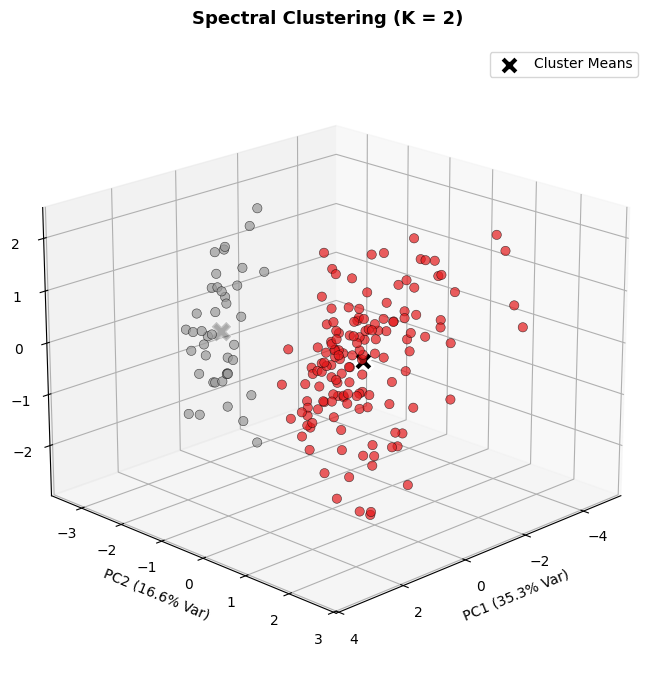

In [15]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

pca_3d = PCA(n_components=3)
x_pca_3d = pca_3d.fit_transform(scaled_data)
var_exp = pca_3d.explained_variance_ratio_ * 100

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

k = 2
spectral = SpectralClustering(
    n_clusters=k,
    affinity="nearest_neighbors", 
    n_neighbors=15,
    assign_labels="kmeans",
    random_state=42,
    n_jobs=-1,
)
labels = spectral.fit_predict(scaled_data)

centers_3d = np.array([
    x_pca_3d[labels == cluster_id].mean(axis=0) 
    for cluster_id in range(k)
])

ax.scatter(
    x_pca_3d[:, 0],
    x_pca_3d[:, 1],
    x_pca_3d[:, 2],
    c=labels,
    cmap="Set1",
    s=45,
    alpha=0.7,
    edgecolors="k",
    linewidths=0.4,
)

ax.scatter(
    centers_3d[:, 0],
    centers_3d[:, 1],
    centers_3d[:, 2],
    c="black",
    marker="X",
    s=200,
    linewidths=2,
    edgecolors="white",
    label="Cluster Means",
    zorder=10,
)

ax.set_title(f"Spectral Clustering (K = {k})", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel(f"PC1 ({var_exp[0]:.1f}% Var)", fontsize=10)
ax.set_ylabel(f"PC2 ({var_exp[1]:.1f}% Var)", fontsize=10)
ax.set_zlabel(f"PC3 ({var_exp[2]:.1f}% Var)", fontsize=10)

ax.view_init(elev=20, azim=45)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

We see that there is a split in 3D PCA which is perfectly captured using Spectral Clustering

# Survival Function

We will now apply both Kaplan-Meier and Cox Regression using the survival library lifelines.

`Kaplan-Meier`: Non-parametric method which makes no assumption about the underlying distribution of data.
It uses the distinct event times, as well as the number of subjects who experience the event at time T, the patients still at risk, and finally the censored patients to compute the probability of survivong past $T_j$

`Cox-Regression`: Semi-parametric method as the distribution of the outcome remains unknown even if it is based on a parametric regression mode. Cox proposes a partial likelihood which depends only on the coefficients vector

In [16]:
y = pd.concat([event,duration], axis = 1)
y

,survival_status,survival_time
0,0,999
1,1,163
2,1,435
3,1,53
4,0,2043
...,...,...
182,1,385
183,1,634
184,0,1895
185,1,382


In [17]:
# We first split data K=2
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data)

model = KMeans(n_clusters=2, random_state=42, init="k-means++")
cluster_labels = model.fit_predict(scaled_data)

# Splitting data into separate groups
df = pd.DataFrame(data).copy()
df["cluster"] = cluster_labels
df["event"] = y["survival_status"]
df["duration"] = y["survival_time"]


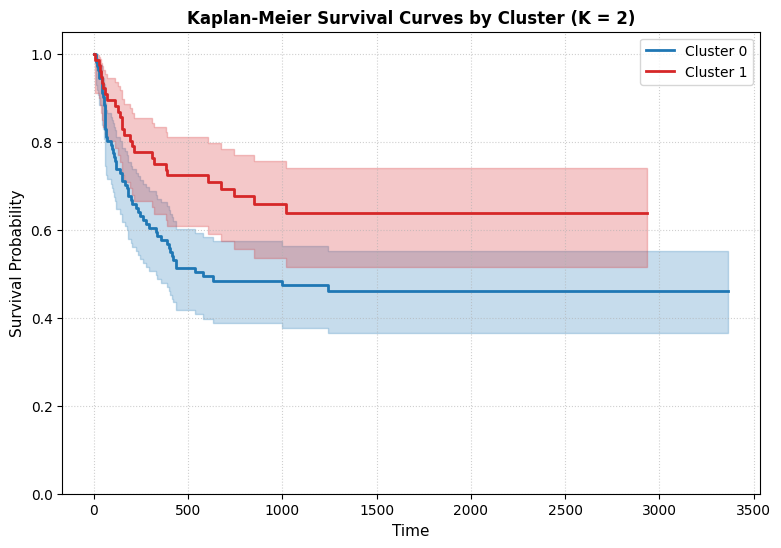

In [18]:
kmf0 = KaplanMeierFitter()
kmf1 = KaplanMeierFitter()

group0 = df[df["cluster"] == 0]
group1 = df[df["cluster"] == 1]

kmf0.fit(
    durations=group0["duration"],
    event_observed = group0["event"],
    label="Cluster 0"
)

kmf1.fit(
    durations=group1["duration"],
    event_observed = group1["event"],
    label="Cluster 1"
)

plt.figure(figsize=(9, 6))
ax = kmf0.plot_survival_function(ci_show=True, color="#1f77b4", lw=2)
kmf1.plot_survival_function(ax=ax, ci_show=True, color="#d62728", lw=2)

plt.title("Kaplan-Meier Survival Curves by Cluster (K = 2)", fontweight="bold")
plt.xlabel("Time", fontsize=11)
plt.ylabel("Survival Probability", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.ylim(0, 1.05)
plt.show()


In [29]:
c0, c1 = df[df["cluster"] == 0], df[df["cluster"] == 1]
lr_results = logrank_test(
    c0["duration"], c1["duration"], c0["event"], c1["event"]
)
print(f"Log-Rank Test p-value: {lr_results.p_value:.5f}\n")

Log-Rank Test p-value: 0.01199



There is a clear difference in both survival gropus, where patients in group 1 have a higher survival probability.

In [33]:
# Applying regularized Cox model
# lasso is with l1_ratio = 1, ridge is with l1_ratio = 0, elastic net is 0.5
cph_stratified = CoxPHFitter(penalizer=0.1, l1_ratio=0.5)
cph_stratified.fit(
    df,
    duration_col="duration",
    event_col="event",
    strata=["cluster"],
)

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>

In [34]:
cph_unadjusted = CoxPHFitter()
cph_unadjusted.fit(df[['duration', 'event', 'cluster']], duration_col='duration', event_col='event')
cph_unadjusted.print_summary()

<lifelines.CoxPHFitter: fitted with 187 total observations, 102 right-censored observations>
             duration col = 'duration'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 187
number of events observed = 85
   partial log-likelihood = -416.48
         time fit was run = 2026-10-28 17:49:59 UTC

---
           coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                  
cluster   -0.58      0.56      0.24           -1.05           -0.12                0.35                0.89

           cmp to     z    p  -log2(p)
covariate                             
cluster      0.00 -2.48 0.01      6.24
---
Concordance = 0.57
Partial AIC = 834.96
log-likelihood ratio test = 6.54 on 1 df
-log2(p) of ll-ratio test = 6.57

In [35]:
cph_unstratified = CoxPHFitter(penalizer=0.1, l1_ratio=0.5)
cph_unstratified.fit(df, duration_col="duration", event_col="event")

feature_importance = pd.DataFrame(
    {
        "Log-Hazard Coeff (β)": cph_unstratified.params_,
        "Hazard Ratio (exp(β))": cph_unstratified.hazard_ratios_,
        "95% CI Lower": np.exp(
            cph_unstratified.confidence_intervals_["95% lower-bound"]
        ),
        "95% CI Upper": np.exp(
            cph_unstratified.confidence_intervals_["95% upper-bound"]
        ),
        "p-value": cph_unstratified.summary["p"],
    }
).sort_values(by="Hazard Ratio (exp(β))", ascending=False)

print(feature_importance)

                Log-Hazard Coeff (β)  Hazard Ratio (exp(β))  95% CI Lower  \
covariate                                                                   
RecipientRh             1.785070e-01               1.195431      0.660652   
Riskgroup               1.335738e-01               1.142906      0.754147   
Rbodymass               9.861527e-03               1.009910      0.997890   
Donorage                7.596373e-04               1.000760      0.975555   
Recipientage            1.241095e-07               1.000000      0.999782   
CD34kgx10d6            -3.362468e-08               1.000000      0.999944   
cluster                -4.384476e-07               1.000000      0.999065   
Stemcellsource         -2.731212e-02               0.973057      0.561504   
CD3dkgx10d8            -3.714731e-02               0.963534      0.897684   

                95% CI Upper   p-value  
covariate                               
RecipientRh         2.163100  0.555217  
Riskgroup           1.732067 

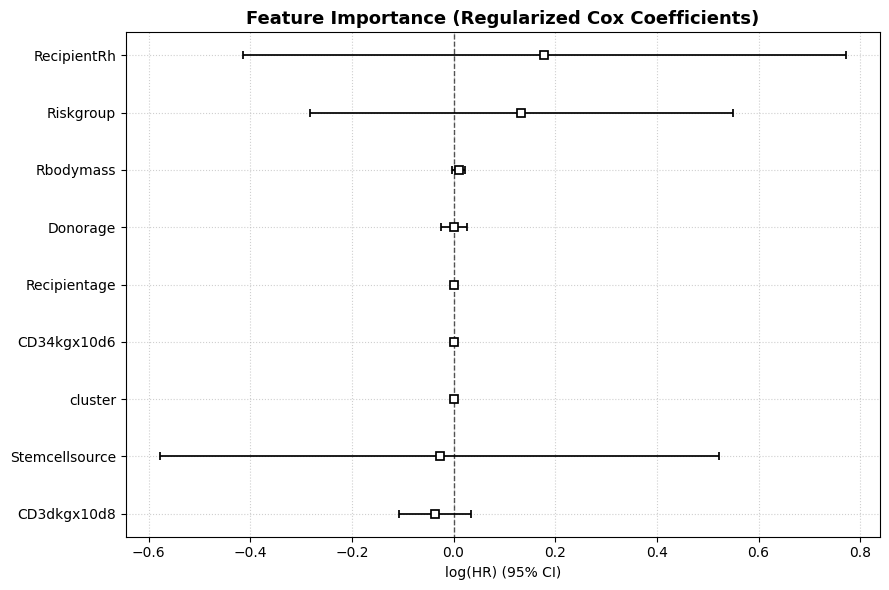

In [36]:
plt.figure(figsize=(9, 6))
cph_unstratified.plot()

plt.title(
    "Feature Importance (Regularized Cox Coefficients)",
    fontsize=13,
    fontweight="bold",
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()